In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

def adjust_bars(bars, ax, values):
    labels = ['n/a' if h == 0 else str(h) for h in values]
    texts = ax.bar_label(bars, labels=labels, padding=-16)
    
    # Adjust "n/a" labels to y=5
    for i, (bar, text) in enumerate(zip(bars, texts)):
        if values[i] == 0:
            x = bar.get_x() + bar.get_width() / 2
            text.set_position((x, 0))
        text.set_verticalalignment('bottom')

# 5.996

baselines = [15, 23.12, 19.89]
baselines_cifar = [37.62,  38.77, 40.92]
xbaselines = [-4.5,-3.5, -2.5]
valbaselines = ["Rand.","HMAX", "Scat."]

nymeria = [5.96]
nymeria_cifar = [34.19]
xnymeria = [1.5]
valnymeria = ["AE"]

samedomainx = [-1,0,1]
samedomain_cifar = [70.4, 80.3, 80.8]
samedomain_i1k = [0,0,0]
samedomain = ["LPL","SH","SCFF"]


humans = np.array([88, 94.9]).mean()
humans_cifar = [93.91]
xhumans = [9]
valhumans = ["Humans"]

kitti = [13.62, 15.34]
kitti_cifar = [44.03, 53.14]
xkitti = [2.5, 3.5]
val_kitti = ["Prednet",'E-SSL\n/S /L\n/SMC']

categories = ['E-SSL\n/S /L\n/SMC','E-SSL\n/S /L','E-SSL\n/S','E-SSL']
xmodels = [4.5, 5.5, 6.5, 7.5]
values = [52.70, 58.09, 67.09, 71.036]
values_cifar = [71.52, 77.11, 82.54, 83.03]

# Create the barplot
fig, ax = plt.subplots(2, 1, figsize=(15, 6))
plt.rcParams.update({"font.size": 12})
plt.rcParams["font.family"] = "Helvetica"

#ax[0].set_title('Object recognition', fontsize=16)
bars = ax[0].bar(xbaselines, baselines, color='tab:grey',width=0.95)
ax[0].bar_label(bars, padding=-16)

bars = ax[0].bar(xmodels, values, color='tab:blue',width=0.95)
ax[0].bar_label(bars, padding=-16)

ax[0].hlines(humans, xbaselines[0], xmodels[-1], colors="black",linestyle="--")
ax[0].text(xmodels[-1], humans-2, "Humans",  color="black")

#bars = ax[0].bar(xhumans, humans, color='tab:orange',width=0.95)
#ax[0].bar_label(bars, padding=-16)

bars = ax[0].bar(xkitti, kitti, color='tab:red',width=0.95)
ax[0].bar_label(bars, padding=-16)

bars = ax[0].bar(samedomainx, samedomain_i1k, color='tab:green',width=0.95)
adjust_bars(bars, ax[0],samedomain_i1k)

#bars = ax[0].bar(xnymeria, nymeria, color='tab:blue',width=0.95)
#adjust_bars(bars, ax[0],nymeria)

ax[0].set_ylabel('I1K image rec.')
ax[0].set_xticks([])
ax[0].set_yticks([0, 25, 50, 75])

############################################################

#plt.figure(figsize=(8, 3.5))
bars = ax[1].bar(xbaselines, baselines_cifar, color='tab:grey',width=0.95)
ax[1].bar_label(bars, padding=-16)

bars = ax[1].bar(xmodels, values_cifar, color='tab:blue',width=0.95)
ax[1].bar_label(bars, padding=-16)

ax[1].hlines(humans_cifar, xbaselines[0], xmodels[-1], colors="black",linestyle="--")
ax[1].text(xmodels[-1], humans, "Humans",  color="black")


bars = ax[1].bar(xkitti, kitti_cifar, color='tab:red',width=0.95)
ax[1].bar_label(bars, padding=-16)

bars = ax[1].bar(samedomainx, samedomain_cifar, color='tab:green',width=0.95)
ax[1].bar_label(bars, padding=-16)


ax[1].set_ylabel('Cifar10 image rec.')
ax[1].set_yticks([0, 25, 50, 75])

ax[1].set_xticks(xmodels+xbaselines+samedomainx+xkitti,
                 categories+valbaselines+samedomain+val_kitti, 
                 rotation=0)


patches = []
v1 = ["None", "Kitti", "Cifar10", "Nymeria"]
colors = ["tab:grey", "tab:red", "tab:green","tab:blue"]
for c, l in zip(colors, v1 ):
    patches.append(mpatches.Patch(facecolor=c, label=l))

ax[0].legend(handles=patches,loc=(0.01,0.5),ncol=2,title="Pre-training data")

ax[0].set_ylim([-3,100])
ax[1].set_ylim([20,100])

plt.savefig("/home/arthur/postdoc/projects/Nymeria/mainresult_cifar.svg", dpi=800, bbox_inches='tight')


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

aamocov3 = [43.652, 43.92, 44.23, 43.66, 43.27, 43.47]
aasimclr = [37.84, 39.75, 40.37, 40.73, 41.31,40.29]
aavicreg = [37.34,	39.12,	38.93,	38.87,	38.28,	38.26]

aamocov3_depth = [0.739, 0.736, 0.756, 0.756, 0.76, 0.77]
aasimclr_depth = [0.729, 0.727, 0.726, 0.73, 0.734, 0.737]
aavicreg_depth = [0.727,	0.724,	0.723,	0.722,	0.736,	0.734]

aamocov3_davis = [38.396,	35.29,	36.052,	36.096,	37.266,	36.746]
aasimclr_davis = [39.98,	36.902,	40.338,	40.218,	38.6,	37.768]
aavicreg_davis = [41.7475,	35.5875,	36.465,	38.7075,	36.895,	37.4225]


aamocov3_places = [41.92, 41.82, 41.59, 41.2, 40.9, 40.91]
aasimclr_places = [40.05, 41.18,	41.54,	41.12,	41.18,	41.01]
aavicreg_places = [39.73,	40.87,	41.19,	41.03,	40.76,	40.7]

aamocov3_semseg = [34.46	,34.43	,34.69	,33.05	,33.53	,32.9]
aasimclr_semseg = [35.4	, 32.8, 32.29,	32.23, 29.69,	29.41]
aavicreg_semseg = [26.28,	27.43,	26.64,	26.49,	26.25,	24.15]


aamocov3_sintel= [ 4.53,	4.58,	4.52,	4.51,	4.54,	4.61]
aasimclr_sintel = [4.48,	4.51,	4.64,	4.62,	4.66,	4.54]
aavicreg_sintel = [4.486666667,	4.503333333,	4.476666667,	4.603333333,	4.656666667,	4.663333333]


aamocov3_mv = [0.134,	0.134,	0.137,	0.136,	0.137,	0.139]
aasimclr_mv = [0.134,	0.137,	0.135,	0.142,	0.14,	0.146]
aavicreg_mv = [0.1307,	0.1332,	0.1312,	0.132,	0.1369,	0.143]

fig, ax = plt.subplots(2,3, figsize=(13, 6))
plt.rcParams.update({"font.size": 16})
def three_digits(x, pos):
    # ':.3g' rounds to 3 significant figures
    # '{:#.3g}' forces trailing zeros
    formatted = f"{x:#.3g}"
    
    # Clean up: remove a trailing dot if the number is an integer (e.g., '123.')
    if formatted[1] == ".":
        return formatted[:-1]
    return formatted
def lower_better(title):
    return "Depth" in title or "Pose" in title or "Sintel" in title

def add_plot(ax, title, values, labelx=True):
    x = np.log(np.array([1,5,10,25,50,100]))
    colors = ["tab:blue", "tab:cyan", "tab:purple"]
    linestyles =["-", "--","dotted"]
    xms = np.array([1,5,10,25,50,100])*0.2
    xms = [0.2, 1, 2, 5, 10, 20]
    
    for i in range(len(values)):
        ax.plot(x, values[i], color=colors[i], linestyle=linestyles[i], marker="x")
    best = np.argmin(np.array(values).mean(axis=0)) if lower_better(title) else np.argmax(np.array(values).mean(axis=0))
    ax.vlines(x[best],np.min(values), np.max(values) , color="tab:red", linestyle="dashdot")
    #ax.plot(x, np.array(values).mean(axis=0), color="tab:red", marker="x")
    #ax.set_title("Impact of time window on TC+SMC")
    ax.set_ylabel(title)
    ax.set_xticks(x,xms)
    if labelx:
        ax.set_xlabel(r' Temporal tuning ($\Delta T$ sec.)')
    ax.annotate('', xy=(-0.32, 0.35 if lower_better(title) else 0.65 ), xytext=(-0.32, 0.65 if lower_better(title) else 0.35),
        xycoords='axes fraction',
         arrowprops=dict(facecolor='black', shrink=0.01, width=0.6, headwidth=4),
         horizontalalignment='center', rotation=90)
    ax.yaxis.set_major_formatter(FuncFormatter(three_digits))
    if title == "MVImgNet loss":
        ax.set_yticks([0.13, 0.14])
    if "Instance" in title:
        ymax = 41
        ax.text(x[1]-0.3, ymax, "***",  color="tab:red")
        ax.text(x[2]-0.2, ymax, "**",  color="tab:red")
        ax.text(x[3]-0.1, ymax, "*",  color="tab:red")
        ax.text(x[4]-0.1, ymax, "*",  color="tab:red")
        ax.text(x[5]-0.2, ymax, "**",  color="tab:red")

    #xms = [0.2, 1, 2, 5, 10, 20]

add_plot(ax[0][0], "Object rec.", (aamocov3, aasimclr, aavicreg), labelx=False)
add_plot(ax[0][1], "Scene rec.", (aamocov3_places, aasimclr_places, aavicreg_places), labelx=False)
add_plot(ax[0][2], "Semantic segm.", (aamocov3_semseg, aasimclr_semseg, aavicreg_semseg), labelx=False)
add_plot(ax[1][0], "Instance segm.", (aamocov3_davis, aasimclr_davis, aavicreg_davis))
add_plot(ax[1][1], "Depth est.", (aamocov3_depth, aasimclr_depth, aavicreg_depth))
#add_plot(ax[1][2], "Sintel EPE", (aamocov3_sintel, aasimclr_sintel, aavicreg_sintel))
add_plot(ax[1][2], "Pose est.", (aamocov3_mv, aasimclr_mv, aavicreg_mv))


legend_elements = [
    Line2D([0], [0], color="tab:blue", lw=2, label="E-MoCoV3"),
    Line2D([0], [0], color="tab:cyan", lw=2, linestyle="--", label="E-SimCLR"),
    Line2D([0], [0], color="tab:purple", lw=2, linestyle="dotted", label="E-VICReg"),
    Line2D([0], [0], color="tab:red", lw=2, linestyle="dashdot", label="Best"),
    #Line2D([0], [0], color="tab:red", lw=2, label="Average"),

]
ax[0][2].legend(handles=legend_elements, loc=(0.1,0.03))
#ax[1][2].legend(handles=legend_elements, loc=(0.07,0.26))

#ax[0][0].text(-0.2, 1.15, "A", transform=ax[0][0].transAxes,fontsize=14,fontweight="bold",va="top")
#ax[1][0].text(-0.2, 1.15, "B", transform=ax[1][0].transAxes,fontsize=14,fontweight="bold",va="top")

plt.tight_layout()
plt.savefig("/home/arthur/postdoc/projects/Nymeria/timewindow.svg",dpi=400)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from scipy import stats
import matplotlib.ticker as mtick
from matplotlib.ticker import FuncFormatter
#a0 = np.array([42.27, 40.074, 32.34, 0.888, 6.73, 70.71)
#a003 = np.array([43.26, 43.26, 33.39, 0.774, 6.58, 72.02])
#a01 = np.array([44.23, 41.59, 34.69, 0.756, 6.58, 72.02])
#a03 = np.array([43.92, 42.22, 34.52, 0.736, 6.58, 72.02])
#a1 = np.array([42.82, 42.07, 33.85, 0.708, 6.58, 72.02])

aamocov3 = [42.27, 43.26, 44.23, 43.92, 42.82]
aasimclr = [39.24, 40.53,	41.31,	40.81,	39.59]
aavicreg = [36.48, 37.91,	38.87,	38.87,	38.6]

aamocov3_depth = [0.795, 0.774,	0.756,	0.736,	0.708]
aasimclr_depth = [0.785, 0.764,	0.734,	0.736,	0.716]
aavicreg_depth = [0.807, 0.777,	0.722,	0.744,	0.726]

aamocov3_places = [40.074, 40.69,	41.59	,42.22	,42.07]
aasimclr_places = [38.63, 40.89, 41.18,	41.96,	41.53]
aavicreg_places = [37.86, 38.96,	41.03,	40.76,	41.1]

aamocov3_semseg = [32.34, 33.39,	34.69,	34.52,	33.85]
aasimclr_semseg = [26.84, 29.78,	29.69,	31.29,	30.28]
aavicreg_semseg = [23.21, 23.82,	26.49,	26.23,	26.28]

aamocov3_davis= [35.762, 35.714,	36.052,	38.136,	37.876]
aasimclr_davis = [34.056, 38.464,	38.6,	38.682,	40.838]
aavicreg_davis = [35.744, 36.332,	37.158,	37.758,	38.56]

aamocov3_sintel= [4.63, 4.576666667,	4.453333333,	4.593333333,	4.553333333]
aasimclr_sintel = [4.74, 4.61,	4.683333333,	4.626666667,	4.523333333]
aavicreg_sintel = [4.9, 4.76,	4.585,	4.715,	4.54]

aamocov3_mvimgnet = [0.164,	0.144,	0.137,	0.129,	0.126]
aasimclr_mvimgnet = [0.203,	0.155,	0.14,	0.131,	0.125]
aavicreg_mvimgnet = [0.211,	0.173,	0.132,	0.146,	0.133]

fig, ax = plt.subplots(2,3, figsize=(13, 6))
plt.rcParams.update({"font.size": 16})

def three_digits(x, pos):
    # ':.3g' rounds to 3 significant figures
    # '{:#.3g}' forces trailing zeros
    formatted = f"{x:#.3g}"
    
    # Clean up: remove a trailing dot if the number is an integer (e.g., '123.')
    if formatted[1] == ".":
        return formatted[:-1]
    return formatted

def lower_better(title):
    return "Depth" in title or "Pose" in title or "Sintel" in title

def add_plot(ax, title, values, labelx=True):
    x = np.log(np.array([0.01,0.03,0.1,0.3,1]))
    colors = ["tab:blue", "tab:cyan", "tab:purple"]
    linestyles =["-", "--","dotted"]
    
    for i in range(len(values)):
        ax.plot(x, values[i], color=colors[i], linestyle=linestyles[i], marker="x", alpha=1)

    best = np.argmin(np.array(values).mean(axis=0)) if lower_better(title) else np.argmax(np.array(values).mean(axis=0))
    ax.vlines(x[best],np.min(values), np.max(values) , color="tab:red", linestyle="dashdot")

    #ax.set_title("Impact of time window on TC+SMC")
    ax.set_ylabel(title)
    ax.set_xticks(x,[0,0.03,0.1,0.3,1])
    if labelx:
        ax.set_xlabel(r'Visuomotor sensitivity $\alpha_{\text{SMC}}$')
    ax.annotate('', xy=(-0.32, 0.35 if lower_better(title) else 0.65 ), xytext=(-0.32, 0.65 if lower_better(title) else 0.35),
            xycoords='axes fraction',
             arrowprops=dict(facecolor='black', shrink=0.01, width=0.6, headwidth=4),
             horizontalalignment='center', rotation=90)
    ax.yaxis.set_major_formatter(FuncFormatter(three_digits))
    if title == "MVImgNet loss":
        ax.set_yticks([0.12, 0.15, 0.18, 0.21])
    if "Instance" in title:
        ax.text(x[0]-0.2, 40.2, "***",  color="tab:red")
        ax.text(x[1]-0.2, 40.2, "**",  color="tab:red")
        ax.text(x[2]-0.2, 40.2, "*",  color="tab:red")
        ax.text(x[3]-0.2, 40.4, "ns",  color="tab:red")

    #if title == "NYUv2 rmse":
    #    ax.set_yticks([0.1, 0.15, 0.2])
    #xms = [0.2, 1, 2, 5, 10, 20]

add_plot(ax[0][0], "Object rec.", (aamocov3, aasimclr, aavicreg),labelx=False)
add_plot(ax[0][1], "Scene rec.", (aamocov3_places, aasimclr_places, aavicreg_places),labelx=False)
add_plot(ax[0][2], "Semantic segm.", (aamocov3_semseg, aasimclr_semseg, aavicreg_semseg),labelx=False)
add_plot(ax[1][0], "Instance segm.", (aamocov3_davis, aasimclr_davis, aavicreg_davis))
add_plot(ax[1][1], "Depth est.", (aamocov3_depth, aasimclr_depth, aavicreg_depth))
#add_plot(ax[1][2], "Sintel EPE", (aamocov3_sintel, aasimclr_sintel, aavicreg_sintel))
add_plot(ax[1][2], "Pose est.", (aamocov3_mvimgnet, aasimclr_mvimgnet, aavicreg_mvimgnet))


legend_elements = [
    Line2D([0], [0], color="tab:blue", lw=2, label="E-MoCoV3"),
    Line2D([0], [0], color="tab:cyan", lw=2, linestyle="--", label="E-SimCLR"),
    Line2D([0], [0], color="tab:purple", lw=2, linestyle="dotted", label="E-VICReg"),
    Line2D([0], [0], color="tab:red", lw=2, linestyle="dashdot", label="Best"),


]
ax[1][2].legend(handles=legend_elements, loc=(0.3,0.37))

plt.tight_layout()
plt.savefig("/home/arthur/postdoc/projects/Nymeria/actionweight.svg", dpi=500)
plt.show()

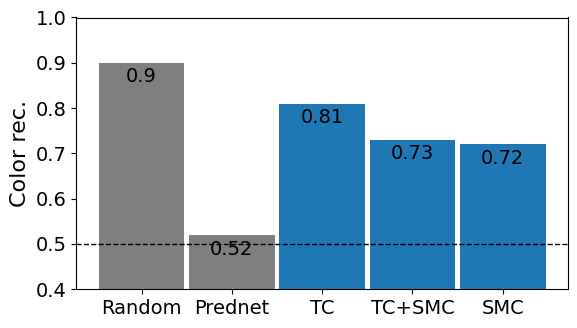

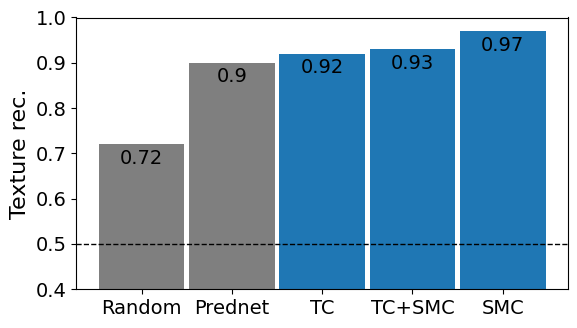

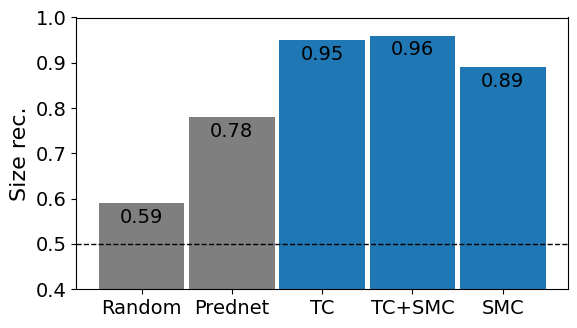

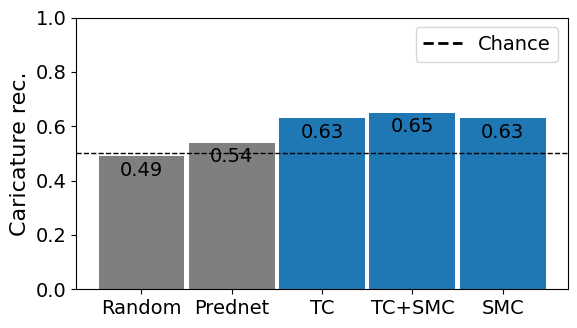

In [31]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
# Data for the barplot
categories = ['Random', "MoCoV3", 'Bio-MoCoV3','Bio-SimCLR','Bio-VICReg']
random = [0.90, 0.72, 0.59,0.49]
#mocov3_i1k = [0.60, 0.94, 0.98, 0.74]
mocov3 = [0.65, 0.91, 0.96, 0.64]
prednet = [0.52, 0.90,0.78,0.54]
best = [0.73,0.93,0.96,0.65]
aasimclr = [0.86,0.92,0.93,0.62]
aavicreg = [0.84, 0.90, 0.89, 0.65]
aamocov30= [0.72, 0.97, 0.89, 0.63]

mocov3tt = [0.81,0.92,0.95,0.63]
vicregtt=[0.92,0.82,0.87,0.58]
simclrtt=[0.91,0.88,0.91,0.57]

title = ["Color rec.","Texture rec.", "Size rec.", "Caricature rec."]
# Create the barplot

Xmoco = np.arange(2)*3.5
Xsimclr = np.arange(2)*3.5 + 1
Xvicreg = np.arange(2)*3.5 + 2

for i in range(4):
    plt.rcParams.update({"font.size": 14})
    plt.figure(figsize=(6, 3.5))

    bars = plt.bar([-4, -3, -2, -1, 0], random[i:i+1]+prednet[i:i+1]+
                   mocov3tt[i:i+1] + 
                   best[i:i+1] +aamocov30[i:i+1],  width=0.95,  color=['tab:grey', 'tab:grey', 'tab:blue','tab:blue',"tab:blue"])
    plt.bar_label(bars, padding=-17)

    plt.ylabel(title[i], fontsize=16)
    plt.axhline(y=0.5, color='black', linestyle='--', linewidth=1)
    #plt.text(x=-0.35, y=0.37, s='Chance', color='black', va='bottom')
    #plt.yticks([0,0.2,0.4,0.6,0.8])
    plt.ylim(0 if i == 3 else 0.4,1)
    #if i == 3:
    plt.xticks((-4, -3, -2, -1, 0), ("Random","Prednet","TC", "TC+SMC","SMC")) #, r"SMC, $\Delta T=0.2$"
    #plt.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)

    if i == 3:
        plt.legend(loc="best", handles=[Line2D([0], [0], color="black", lw=2, linestyle="--", label="Chance")])
    #else:
    #    plt.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)
        #plt.xticks(labels=[])


    # Adjust layout and display
    plt.tight_layout()
    plt.savefig(f"/home/arthur/postdoc/projects/Nymeria/attr_{title[i]}v2.svg", dpi=300, bbox_inches='tight')
    plt.show()

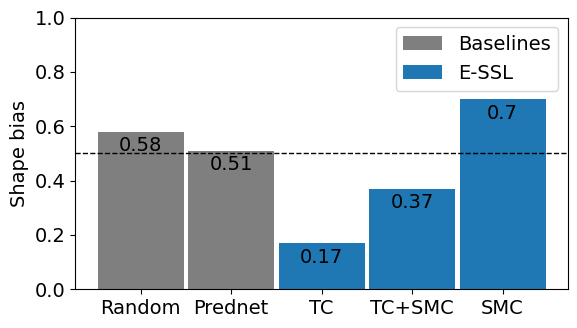

In [122]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

weights_aamocov3 = [0.94, 0.94, 0.89, 0.85, 0.73]
weight_aasimclr = [0.9, 0.85, 0.78, 0.74, 0.63]
neurons_aasimclr = [0.85, 0.92, 0.85, 0.76, 0.54]
neurons_aamocov3 = [0.90, 0.92, 0.88, 0.68, 0.32]
weight_aavicreg = [0.78, 0.76, 0.63, 0.56, 0.39]
neurons_aavicreg = [0.69, 0.87, 0.83, 0.67, 0.23]

x = np.arange(0, 5)
plt.figure(figsize=(6, 3.5))
plt.rcParams.update({"font.size": 14})
############################################

#aamocov3 = [17.25,	23.35,	24.2, 24.7,	37.29] #tt0, 69.91 | 89.79, sn1
#aasimclr = [8.74,	20.83,	16.37,	25.49,	39.66]#tt0 66.95 | 86.83
#aavicreg = [9.12,	10.04,	29,	17.29	,25.29]

#aamocov3 = np.array([17.25, 37.29, 69.91])/100#, 89.79] #tt0, 69.91 | 89.79, sn1
#aasimclr = np.array([8.74, 39.66, 66.95])/100#, 86.83]#tt0 66.95 | 86.83
#aavicreg = np.array([9.12, 29, 68.37 ])/100

aamocov3 = np.array([17, 37,  70])/100#, 89.79] #tt0, 69.91 | 89.79, sn1
aasimclr = np.array([8, 39])/100#, 86.83]#tt0 66.95 | 86.83
aavicreg = np.array([9, 29])/100
#aavicreg = [9.12,	10.04,	29,	17.29	,25.29]

Xmoco = np.arange(len(aamocov3))*3.5
Xsimclr = np.arange(len(aamocov3))*3.5 + 1
Xvicreg = np.arange(len(aamocov3))*3.5 + 2

#mocov3_i1k = [0.60, 0.94, 0.98, 0.52]
#mocov3 = [0.65, 0.91, 0.96, 0.21]
bars = plt.bar([-4], [0.58], width=0.95, color='tab:grey')
plt.bar_label(bars, padding=-17)

bars = plt.bar([-3], [0.51], width=0.95, color='tab:grey')
plt.bar_label(bars, padding=-17)

#bars = plt.bar([-2], [0.20], width=0.95, color='tab:grey')
#plt.bar_label(bars, padding=-17)

#plt.bar_label(bar)
bars = plt.bar([-2, -1, 0], aamocov3, width=0.95, color='tab:blue')
plt.bar_label(bars, padding=-17)



plt.xticks((-4, -3, -2, -1, 0), ("Random","Prednet", "TC", "TC+SMC", "SMC"), rotation=0) #, r"SMC, $\Delta T=0.2$"
plt.ylabel("Shape bias")
plt.yticks([0,0.2,0.4,0.6,0.8,1])
plt.ylim(0,1)
#ax[0].hlines(50, X[0]-0.5, X[-1] + 0.5, colors="black")

#add_plot(ax[0], "Shape bias", (aamocov3, aasimclr, aavicreg))
plt.axhline(y=0.5, color='black', linestyle='--', linewidth=1)

patch0 = mpatches.Patch(facecolor='tab:grey', label='Baselines')
patch1 = mpatches.Patch(facecolor='tab:blue', label='E-SSL')
#patch2 = mpatches.Patch(facecolor='tab:cyan', label='Bio-SimCLR')
#patch3 = mpatches.Patch(facecolor='tab:purple', label='Bio-VICReg')
plt.legend(handles=[patch0,patch1],loc="best")

#ax[0].text(-0.1, 1.05, "A", transform=ax[0].transAxes,fontsize=14,fontweight="bold",va="top")
#ax[1].text(-0.1, 1.05, "B", transform=ax[1].transAxes,fontsize=14,fontweight="bold",va="top")
#ax[2].text(-0.1, 1.05, "C", transform=ax[2].transAxes,fontsize=14,fontweight="bold",va="top")

plt.tight_layout()
plt.savefig("/home/arthur/postdoc/projects/Nymeria/shape_biasv2.svg", dpi=300, bbox_inches='tight')
plt.show()


(5, 30)
(1, 30)
(5, 30)
 
 
 


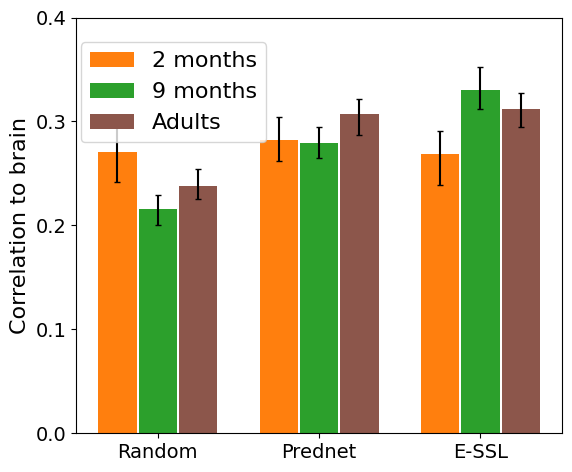

In [124]:
import matplotlib.pyplot as plt
import pandas as pd
import os 
import numpy as np
import matplotlib.patches as mpatches

path = "/home/arthur/postdoc/BabyML/logs/foundcog/"
Y_names = ["all_random_rn50_foundcog_correlation.csv",
           #"all_sup_rn50_foundcog_correlation.csv",
            #"all_mocov3_rn50_foundcog_correlation.csv",
            "prednet_foundcog_correlation.csv",
           #"all_mocov3_sn10_e20-74eaqlfh",
           "all_aamocov3_sn10_e20-rjr2i0lz",
           #"all_simclr_sn50_e20-a719we31",
           ]
#Y_names = ["imagenet1k_74eaqlfh-nh0c0rfg","imagenet1k_rjr2i0lz-kk2e79pz","aamocov3_sn1_e20-o1e0cege","aamocov3_sn1_e20_tt0-thvoy3ty", "aamocov3_sn1_gs64_C96-94dbqldd"]
           #"aamocov3_sn1_gs64_C96_dorsal-pqvba55x"]
for j in range(len(Y_names)):
    print(pd.read_csv(os.path.join(path, f"{Y_names[j]}-ep=last-stp=last_foundcog_correlation.csv" if "csv" not in Y_names[j] else Y_names[j]) , header=None).to_numpy().shape)

#Y = np.stack([pd.read_csv(os.path.join(path, f"{Y_names[j]}-ep=last-stp=last_foundcog_correlation.csv" if "csv" not in Y_names[j] else Y_names[j]) , header=None).to_numpy() for j in range(len(Y_names))])
Y = [pd.read_csv(os.path.join(path, f"{Y_names[j]}-ep=last-stp=last_foundcog_correlation.csv" if "csv" not in Y_names[j] else Y_names[j]) , header=None).to_numpy() for j in range(len(Y_names))]

#areas = ["VVC", "LOC","LO", 'LOCla', 'LOClp','hV4','V3v','V2dv','V1',"PHC","FG2","FG4","EVC"]
areas = ["VVC"]

value_index = [5,4,3]#np.arange(3,6)
err_index_low = [11,10,9]
err_index_up = [14,13,12]

std = np.arange(3)
X = np.arange(100)
#X = [1,2,3,5,6,7,9,10,11,13,14,15


fig, ax = plt.subplots(1, len(areas), figsize=(6, 5))
plt.rcParams.update({"font.size": 16})

for i in range(len(areas)):
    for j in range(3):
        norm = Y[0][0,:3][::-1][j]
        #print(norm)
        colors = ["tab:orange","tab:green","tab:brown"]
        for y in range(len(Y)):
            val = np.argmax(Y[y][:,9*i+value_index[j]], axis=0)
            #labels = ax[i,j].bar(X+y/len(Y), Y[y][12*i+value_index]/Y[y][12*i+std], width=0.95/len(Y), color=colors[y])
            means = Y[y][val][15*i+value_index[j]] / norm
            #print(means)
            low_err = means - Y[y][val][15*i+err_index_low[j]] / norm
            up_err = Y[y][val][15*i+err_index_up[j]] / norm - means 
            yerr_fixed = [[low_err], [up_err]]
            # 2. Combine into a 2xN array
            ax.bar(X[4*y+j+(2 if y >= len(Y)-3 else 0)], means , width=0.95, color=colors[j], yerr=yerr_fixed, capsize=2)
            #print(Y[y][val][15*i+value_index[j]])
            
            #ax[i].errorbar(X[4*y+j], Y[y][val][15*i+value_index[j]],yerr=Y[y][val][15*i+err_index_up[j]]-Y[y][val][15*i+err_index_up[j]],color="black")
            #ax[i,j].bar_label(labels, fmt='%.2f', padding=0)
        print(" ")

        #ax[i,j].set_yticks([0,0.2,0.4,0.6,0.8,1])
        #ax[i,j].set_ylim(-0.4,1)
        #ax[i,j].hlines(0.5, X[0]-0.5, X[-1] + 0.5, colors="black")
    #ax[i,j].set_xticks(X,Y_names, rotation=90)
        #ax.hlines(Y[0][0][15*i+std[j]], X[0]-0.5, X[3*len(Y)+3] + 0.5, colors=colors[j])
        ax.set_xticks((3, 7, 11), ("Random","Prednet","E-SSL" ), rotation=0) #, r"SMC, $\Delta T=0.2$"
    #ax.set_title(areas[i])
    #ax.set_yticks((0, 0.2, 0.4, 0.6, 0.8,1)) #, r"SMC, $\Delta T=0.2$"
    ax.set_yticks((0,0.1, 0.2, 0.3, 0.4)) #, r"SMC, $\Delta T=0.2$"

    if i == 0: 
        ax.set_xlabel("")
        ax.set_ylabel("Correlation to brain", fontsize=16)
        #ax.set_ylim(0,0.4)

        #ax.text(14.5, -0.15, "TC+SMC")
        #ax.hlines(-0.1, 13,23, colors="black")

    if i == 0:
        patch1 = mpatches.Patch(facecolor='tab:orange', label='2 months')
        patch2 = mpatches.Patch(facecolor='tab:green', label='9 months')
        patch3 = mpatches.Patch(facecolor='tab:brown', label='Adults')
        ax.legend(handles=[patch1,patch2,patch3],loc=(0.01,0.7))
plt.tight_layout()
plt.savefig("/home/arthur/postdoc/projects/Nymeria/alignmentv2.svg", dpi=400, bbox_inches='tight')
plt.show()

[0.         0.50510204 1.         0.84183673 0.28061224]


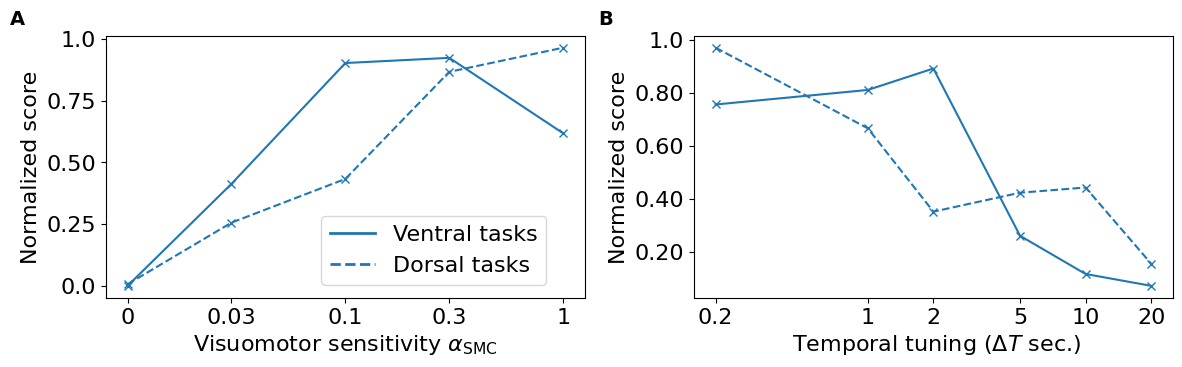

In [73]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from scipy import stats
import matplotlib.ticker as mtick
from matplotlib.ticker import FuncFormatter
#a0 = np.array([42.27, 40.074, 32.34, 0.888, 6.73, 70.71)
#a003 = np.array([43.26, 43.26, 33.39, 0.774, 6.58, 72.02])
#a01 = np.array([44.23, 41.59, 34.69, 0.756, 6.58, 72.02])
#a03 = np.array([43.92, 42.22, 34.52, 0.736, 6.58, 72.02])
#a1 = np.array([42.82, 42.07, 33.85, 0.708, 6.58, 72.02])

aamocov3 = [42.27, 43.26, 44.23, 43.92, 42.82]
aasimclr = [39.24, 40.53,	41.31,	40.81,	39.59]
aavicreg = [36.48, 37.91,	38.87,	38.87,	38.6]

aamocov3_depth = [0.795, 0.774,	0.756,	0.736,	0.708]
aasimclr_depth = [0.785, 0.764,	0.734,	0.736,	0.716]
aavicreg_depth = [0.807, 0.777,	0.722,	0.744,	0.726]

aamocov3_places = [40.074, 40.69,	41.59	,42.22	,42.07]
aasimclr_places = [38.63, 40.89, 41.18,	41.96,	41.53]
aavicreg_places = [37.86, 38.96,	41.03,	40.76,	41.1]

aamocov3_semseg = [32.34, 33.39,	34.69,	34.52,	33.85]
aasimclr_semseg = [26.84, 29.78,	29.69,	31.29,	30.28]
aavicreg_semseg = [23.21, 23.82,	26.49,	26.23,	26.28]

aamocov3_davis= [35.762, 35.714,	36.052,	38.136,	37.876]
aasimclr_davis = [34.056, 38.464,	38.6,	38.682,	40.838]
aavicreg_davis = [35.744, 36.332,	37.158,	37.758,	38.56]

aamocov3_sintel= [4.63, 4.576666667,	4.453333333,	4.593333333,	4.553333333]
aasimclr_sintel = [4.74, 4.61,	4.683333333,	4.626666667,	4.523333333]
aavicreg_sintel = [4.9, 4.76,	4.585,	4.715,	4.54]

aamocov3_mvimgnet = [0.164,	0.144,	0.137,	0.129,	0.126]
aasimclr_mvimgnet = [0.203,	0.155,	0.14,	0.131,	0.125]
aavicreg_mvimgnet = [0.211,	0.173,	0.132,	0.146,	0.133]

fig, ax = plt.subplots(1,2, figsize=(12, 4))
plt.rcParams.update({"font.size": 16})

def three_digits(x, pos):
    # ':.3g' rounds to 3 significant figures
    # '{:#.3g}' forces trailing zeros
    formatted = f"{x:#.3g}"
    
    # Clean up: remove a trailing dot if the number is an integer (e.g., '123.')
    if formatted[1] == ".":
        return formatted[:-1]
    return formatted

def lower_better(title):
    return "Depth" in title or "Pose" in title or "Sintel" in title

def add_plot(ax, title, values, labelx=True,linestyle="-"):
    x = np.log(np.array([0.01,0.03,0.1,0.3,1]))
    colors = ["tab:blue", "tab:cyan", "tab:purple"]
    #linestyles =["-", "--","dotted"]
    #xms = np.array([1,5,10,25,50,100])*0.2
    
    #for i in range(len(values)):
    ax.plot(x, values, color=colors[0], linestyle=linestyle, marker="x", alpha=1)

    best = np.argmin(np.array(values).mean(axis=0)) if lower_better(title) else np.argmax(np.array(values).mean(axis=0))
    #ax.vlines(x[best],np.min(values), np.max(values) , color="tab:red", linestyle="dashdot")

    #ax.set_title("Impact of time window on TC+SMC")
    ax.set_ylabel(title)
    ax.set_xticks(x,[0,0.03,0.1,0.3,1])
    if labelx:
        ax.set_xlabel(r'Visuomotor sensitivity $\alpha_{\text{SMC}}$')
    #ax.annotate('', xy=(-0.32, 0.35 if lower_better(title) else 0.65 ), xytext=(-0.32, 0.65 if lower_better(title) else 0.35),
    #        xycoords='axes fraction',
    #         arrowprops=dict(facecolor='black', shrink=0.01, width=0.6, headwidth=4),
    #         horizontalalignment='center', rotation=90)
    #ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:#.3g}'))
    ax.yaxis.set_major_formatter(FuncFormatter(three_digits))
    if title == "MVImgNet loss":
        ax.set_yticks([0.12, 0.15, 0.18, 0.21])
    if "Davis" in title:
        ax.text(x[0]-0.2, 40.2, "***",  color="tab:red")
        ax.text(x[1]-0.2, 40.2, "**",  color="tab:red")
        ax.text(x[2]-0.2, 40.2, "*",  color="tab:red")
        ax.text(x[3]-0.2, 40.4, "ns",  color="tab:red")

    #if title == "NYUv2 rmse":
    #    ax.set_yticks([0.1, 0.15, 0.2])
    #xms = [0.2, 1, 2, 5, 10, 20]




def normalize_performance(values):
    values = [np.array(v) for v in values]
    values = [(v - np.min(v))/(np.max(v) - np.min(v)) if i < 4 else (v - np.max(v))/(np.min(v) - np.max(v)) for i, v in enumerate(values)]
    return values

aamocov3, aamocov3_places, aamocov3_semseg, aamocov3_davis, aamocov3_depth, aamocov3_mvimgnet = normalize_performance([aamocov3, aamocov3_places, aamocov3_semseg, aamocov3_davis, aamocov3_depth, aamocov3_mvimgnet])

ventral = (aamocov3 + aamocov3_places + aamocov3_semseg)/3
dorsal = (aamocov3_davis + aamocov3_depth + aamocov3_mvimgnet)/3


print(aamocov3)
add_plot(ax[0], "Normalized score", ventral,labelx=True)
add_plot(ax[0], "Normalized score", dorsal,labelx=False,linestyle="--")



aamocov3 = [43.652, 43.92, 44.23, 43.66, 43.27, 43.47]
aasimclr = [37.84, 39.75, 40.37, 40.73, 41.31,40.29]
aavicreg = [37.34,	39.12,	38.93,	38.87,	38.28,	38.26]

aamocov3_depth = [0.739, 0.736, 0.756, 0.756, 0.76, 0.77]
aasimclr_depth = [0.729, 0.727, 0.726, 0.73, 0.734, 0.737]
aavicreg_depth = [0.727,	0.724,	0.723,	0.722,	0.736,	0.734]

aamocov3_davis = [38.396,	35.29,	36.052,	36.096,	37.266,	36.746]
aasimclr_davis = [39.98,	36.902,	40.338,	40.218,	38.6,	37.768]
aavicreg_davis = [41.7475,	35.5875,	36.465,	38.7075,	36.895,	37.4225]


aamocov3_places = [41.92, 41.82, 41.59, 41.2, 40.9, 40.91]
aasimclr_places = [40.05, 41.18,	41.54,	41.12,	41.18,	41.01]
aavicreg_places = [39.73,	40.87,	41.19,	41.03,	40.76,	40.7]

aamocov3_semseg = [34.46	,34.43	,34.69	,33.05	,33.53	,32.9]
aasimclr_semseg = [35.4	, 32.8, 32.29,	32.23, 29.69,	29.41]
aavicreg_semseg = [26.28,	27.43,	26.64,	26.49,	26.25,	24.15]


aamocov3_sintel= [ 4.53,	4.58,	4.52,	4.51,	4.54,	4.61]
aasimclr_sintel = [4.48,	4.51,	4.64,	4.62,	4.66,	4.54]
aavicreg_sintel = [4.486666667,	4.503333333,	4.476666667,	4.603333333,	4.656666667,	4.663333333]


aamocov3_mv = [0.134,	0.134,	0.137,	0.136,	0.137,	0.139]
aasimclr_mv = [0.134,	0.137,	0.135,	0.142,	0.14,	0.146]
aavicreg_mv = [0.1307,	0.1332,	0.1312,	0.132,	0.1369,	0.143]

def add_plot2(ax, title, values, labelx=True,linestyle="-"):
    x = np.log(np.array([1,5,10,25,50,100]))
    colors = ["tab:blue", "tab:cyan", "tab:purple"]
    xms = np.array([1,5,10,25,50,100])*0.2
    xms = [0.2, 1, 2, 5, 10, 20]
    ax.plot(x, values, color=colors[0], linestyle=linestyle, marker="x")
    best = np.argmin(np.array(values).mean(axis=0)) if lower_better(title) else np.argmax(np.array(values).mean(axis=0))
    #ax.vlines(x[best],np.min(values), np.max(values) , color="tab:red", linestyle="dashdot")
    #ax.plot(x, np.array(values).mean(axis=0), color="tab:red", marker="x")
    #ax.set_title("Impact of time window on TC+SMC")
    ax.set_ylabel(title)
    ax.set_xticks(x,xms)
    if labelx:
        ax.set_xlabel(r' Temporal tuning ($\Delta T$ sec.)')
    #ax.annotate('', xy=(-0.32, 0.35 if lower_better(title) else 0.65 ), xytext=(-0.32, 0.65 if lower_better(title) else 0.35),
    #    xycoords='axes fraction',
    #     arrowprops=dict(facecolor='black', shrink=0.01, width=0.6, headwidth=4),
    #     horizontalalignment='center', rotation=90)
    ax.yaxis.set_major_formatter(FuncFormatter(three_digits))
    if title == "MVImgNet loss":
        ax.set_yticks([0.13, 0.14])
    if "Instance" in title:
        ymax = 41
        ax.text(x[1]-0.3, ymax, "***",  color="tab:red")
        ax.text(x[2]-0.2, ymax, "**",  color="tab:red")
        ax.text(x[3]-0.1, ymax, "*",  color="tab:red")
        ax.text(x[4]-0.1, ymax, "*",  color="tab:red")
        ax.text(x[5]-0.2, ymax, "**",  color="tab:red")


aamocov3, aamocov3_places, aamocov3_semseg, aamocov3_davis, aamocov3_depth, aamocov3_mv = normalize_performance([aamocov3, aamocov3_places, aamocov3_semseg, aamocov3_davis, aamocov3_depth, aamocov3_mv])

ventral = (aamocov3 + aamocov3_places + aamocov3_semseg)/3
dorsal = (aamocov3_davis + aamocov3_depth + aamocov3_mv)/3

add_plot2(ax[1], "Normalized score", ventral,labelx=True)
add_plot2(ax[1], "Normalized score", dorsal,labelx=False,linestyle="--")










legend_elements = [
    Line2D([0], [0], color="tab:blue", lw=2, label="Ventral tasks"),
    Line2D([0], [0], color="tab:blue", lw=2, linestyle="--", label="Dorsal tasks"),
    #Line2D([0], [0], color="tab:purple", lw=2, linestyle="dotted", label="Bio-VICReg"),
    #Line2D([0], [0], color="tab:red", lw=2, linestyle="dashdot", label="Best"),
]
ax[0].legend(handles=legend_elements, loc=(0.45,0.05))

ax[0].text(-0.2, 1.1, "A", transform=ax[0].transAxes,fontsize=14,fontweight="bold",va="top")
ax[1].text(-0.2, 1.1, "B", transform=ax[1].transAxes,fontsize=14,fontweight="bold",va="top")

plt.tight_layout()
plt.savefig("/home/arthur/postdoc/projects/Nymeria/actionweight2.svg", dpi=500)
plt.show()

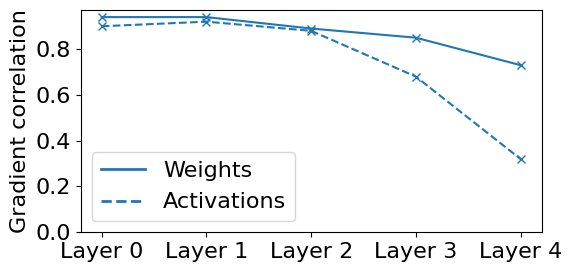

In [92]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

weights_aamocov3 = [0.94, 0.94, 0.89, 0.85, 0.73]
weight_aasimclr = [0.9, 0.85, 0.78, 0.74, 0.63]
neurons_aasimclr = [0.85, 0.92, 0.85, 0.76, 0.54]
neurons_aamocov3 = [0.90, 0.92, 0.88, 0.68, 0.32]
weight_aavicreg = [0.78, 0.76, 0.63, 0.56, 0.39]
neurons_aavicreg = [0.69, 0.87, 0.83, 0.67, 0.23]

x = np.arange(0, 5)
fig, ax = plt.subplots(1,1, figsize=(6,3))
plt.rcParams.update({"font.size": 16})

# Group 1 (blue)
ax.plot(x, weights_aamocov3, color="tab:blue", linestyle="-", marker="x")
ax.plot(x, neurons_aamocov3, color="tab:blue", linestyle="--", marker="x")
#ax.scatter(x, weights_aamocov3, color="tab:blue", "x")
#ax.scatter(x, neurons_aamocov3, color="tab:blue", "x")
# Group 2 (orange)
#ax[0].plot(x, weight_aasimclr, color="tab:cyan", linestyle="--", marker="x")
#ax[1].plot(x, neurons_aasimclr, color="tab:cyan", linestyle="--", marker="x")

#ax[0].plot(x, weight_aavicreg, color="tab:purple", linestyle="dotted", marker="x")
#ax[1].plot(x, neurons_aavicreg, color="tab:purple", linestyle="dotted", marker="x")
#ax[0].set_title("Correlation between weight gradients of TC and SMC")
#ax[1].set_title("Correlation between neuron gradients of TC and SMC")

#ax.set_xlabel("Layers")
ax.set_ylabel("Gradient correlation")
#ax[1].set_ylabel("Neuron correlation")

#ax.set_xticks(size=20)
#ax.set_yticks(size=20)

# ---- Custom legend ----
legend_elements = [
    Line2D([1], [1], color="tab:blue", lw=2, label="Weights"),
    Line2D([1], [1], color="tab:blue", lw=2, linestyle="--",label="Activations"),
    #Line2D([1], [1], color="tab:purple", lw=2, linestyle="dotted",label="Bio-VICReg"),
]
ax.set_xticks(x)
#ax[1].set_xticks(x)

ax.set_yticks([0,0.2,0.4,0.6,0.8])
#ax[1].set_yticks([0,0.2,0.4,0.6,0.8])

ax.set_xticklabels([f"Layer {i}" for i in x], rotation=0)
#ax[1].set_xticklabels([f"Layer {i}" for i in x], rotation=30)

ax.legend(handles=legend_elements, loc="best")

#ax[0].text(-0.1, 1.05, "A", transform=ax[0].transAxes,fontsize=14,fontweight="bold",va="top")
#ax[1].text(-0.1, 1.05, "B", transform=ax[1].transAxes,fontsize=14,fontweight="bold",va="top")
#ax[2].text(-0.1, 1.05, "C", transform=ax[2].transAxes,fontsize=14,fontweight="bold",va="top")

plt.tight_layout()
plt.savefig("/home/arthur/postdoc/projects/Nymeria/corr_tc_smc2.svg", dpi=800)
plt.show()


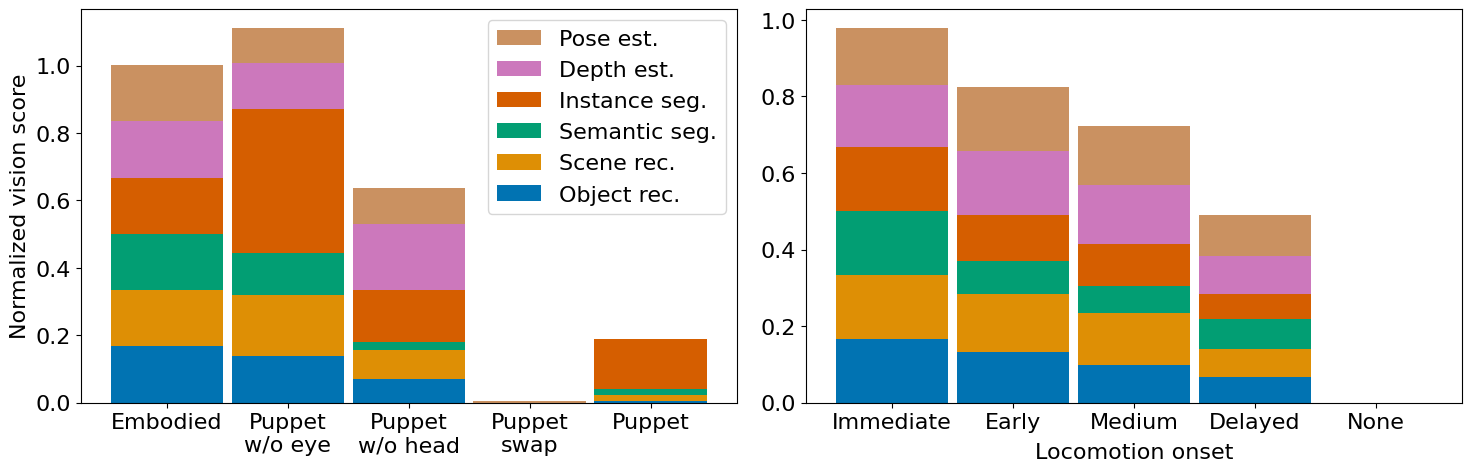

In [109]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
colors = sns.color_palette("colorblind", 6)


aamocov3 = (np.array([44.23, 43.88,	43.06,	42.22, 42.27]) - 42.22)/(44.22 - 42.22)
aasimclr = (np.array([41.31,	40.24, 39.31,		39.1, 39.24]) - 39.1)/(41.31-39.1)
aavicreg = (np.array([38.87,38.71,37.23,	36.48, 36.49]) - 36.48)/(38.87 - 36.48)

aamocov3_depth = (np.array([0.756, 0.763,	0.749,	0.799, 0.795]) - 0.795)/(0.756 - 0.795)
aasimclr_depth = (np.array([0.734, 	0.751,	0.781,0.802, 0.785]) - 0.802)/(0.734 - 0.802)
aavicreg_depth = (np.array([0.722, 0.731,	0.781,	0.828, 0.807]) - 0.828)/(0.722 - 0.828)

aamocov3_places = (np.array([41.59, 41.75,	40.77,	39.9, 40.074]) - 39.9)/(41.59 - 39.9)
aasimclr_places = (np.array([41.18, 41.22,	39.64,	38.93, 38.63]) - 38.63)/(41.18 - 38.63)
aavicreg_places = (np.array([41.03, 40.96,	38.33,	37.87,	37.86]) - 37.86)/(41.03 - 37.86)

aamocov3_semseg = (np.array([34.69, 33.99,	32.44,	32.04, 32.34]) - 32.04) / (34.69 - 32.04)
aasimclr_semseg = (np.array([29.69, 	30.54,	27.1, 27.41, 26.84]) - 26.84) / (29.69 - 26.84)
aavicreg_semseg = (np.array([26.49, 27.4,	20.18,	23.16, 23.21]) - 20.18) / (26.49 - 20.18)

aamocov3_davis= (np.array([36.056, 40.124,	35.842,	33.444, 35.762]) - 33.444) / (36.052 - 33.444) 
aasimclr_davis = (np.array([38.6, 36.798,	37.312,	38.75, 34.056]) - 34.056) / (38.6 - 34.056)
aavicreg_davis = (np.array([37.158,35.84,	36.858,	35.84, 35.744]) - 35.744) / (37.158 - 35.744)

aamocov3_sintel= (np.array([4.453333333,4.526666667,	4.54,	4.53]) - 4.63)
aasimclr_sintel = (np.array([4.683333333,4.633333333,	4.693333333,	4.76]) - 4.74)
aavicreg_sintel = np.array([4.585,4.673333333,4.69, 4.91, 4.9]) - 4.9

aamocov3_mvimgnet = (np.array([0.137, 0.147,	0.147,	0.163, 0.164]) - 0.164) / (0.137 - 0.164)
aasimclr_mvimgnet = (np.array([0.14, 0.145, 0.17, 0.2, 0.203]) - 0.203) / (0.14 - 0.203)
aavicreg_mvimgnet = (np.array([0.132, 0.15,0.167,0.203, 0.211]) - 0.211) / (0.132 - 0.211)


fig, ax = plt.subplots(1,2, figsize=(15, 5))
plt.rcParams.update({"font.size": 16})

x=[0,1,2,3,4,6,7,8,9,10, 12,13,14,15,16]#10,11,12,13]

i1k = np.clip(np.concatenate((aamocov3, aasimclr, aavicreg)),0,100)/6
places = np.clip(np.concatenate((aamocov3_places, aasimclr_places, aavicreg_places)),0,100)/6
segm = np.clip(np.concatenate((aamocov3_semseg, aasimclr_semseg, aavicreg_semseg)),0,100)/6
davis = np.clip(np.concatenate((aamocov3_davis, aasimclr_davis, aavicreg_davis)),0,100)/6
depth = np.clip(np.concatenate((aamocov3_depth, aasimclr_depth, aavicreg_depth)),0,100)/6
mv = np.clip(np.concatenate((aamocov3_mvimgnet, aasimclr_mvimgnet, aavicreg_mvimgnet)),0,100)/6

w=0.93
ax[0].bar(x[:5], i1k[:5], color=colors[0], width=w)
ax[0].bar(x[:5], places[:5], bottom=i1k[:5], color=colors[1], width=w)
ax[0].bar(x[:5], segm[:5], bottom=i1k[:5]+places[:5], color=colors[2], width=w)
ax[0].bar(x[:5], davis[:5], bottom=i1k[:5]+places[:5]+segm[:5], color=colors[3], width=w)
ax[0].bar(x[:5], depth[:5], bottom=i1k[:5]+places[:5]+segm[:5]+davis[:5], color=colors[4], width=w)
ax[0].bar(x[:5], mv[:5], bottom=i1k[:5]+places[:5]+segm[:5]+davis[:5]+depth[:5], color=colors[5], width=w)
ax[0].set_ylabel("Normalized vision score")
ax[0].set_xticks(x[:5],["Embodied","Puppet\nw/o eye", "Puppet\nw/o head", "Puppet\nswap","Puppet\n"], rotation=0)

patches = []
v1 = ["Object rec.", "Scene rec.", "Semantic segm.","Single instance segm.", "Depth est.", "Pose est."][::-1]
v2 = ["ImageNet-1k acc.", "Places365 acc.", "PascalVOC mIoU","Davis2016 IoU", "NYUv2 rmse", "MVImgnet loss"][::-1]
v3 = ["Object rec.", "Scene rec.", "Semantic seg.","Instance seg.", "Depth est.", "Pose est."][::-1]
for c, l in zip(colors[::-1], v3 ):
    patches.append(mpatches.Patch(facecolor=c, label=l))

ax[0].legend(handles=patches,loc="best")

#group_positions = [2, 8, 14]
#groups = ["Bio-MoCoV3","Bio-SimCLR","Bio-VICReg"] # Midpoint of 0,1,2 and 3,4,5
#for pos, label in zip(group_positions, groups):
    #ax.text(pos, -0.30, label, transform=ax.get_xaxis_transform(), 
    #        ha='center', va='top', fontweight='bold')
#    ax.text(pos, 0.95, label, transform=ax.get_xaxis_transform(), 
#        ha='center', va='top', fontweight='bold')


#ax[1][1].legend(handles=legend_elements, loc=(0.3,0.28))

#ax[0][0].text(-0.2, 1.1, "A", transform=ax[0][0].transAxes,fontsize=14,fontweight="bold",va="top")
#ax[1][0].text(-0.2, 1.1, "B", transform=ax[1][0].transAxes,fontsize=14,fontweight="bold",va="top")



aamocov3 = (np.array([42.22,43.018,43.42,43.82,44.23]) - 42.22)/(44.23 - 42.22)
aasimclr = (np.array([39.1,	39.92,	40.03,	40.62,	41.31]) - 39.1)/(41.31-39.1)
aavicreg = (np.array([36.48,37.74,	37.75,	38.47,	38.87]) - 36.48)/(38.87 - 36.48)

aamocov3_depth = (np.array([0.799, 0.773,	0.758,	0.755,	0.756]) - 0.799)/(0.755 - 0.799)
aasimclr_depth = (np.array([0.802, 	0.751,	0.781,0.802, 0.785]) - 0.802)/(0.751 - 0.802)
aavicreg_depth = (np.array([0.828, 0.769,	0.764,	0.765,	0.722]) - 0.828)/(0.722 - 0.828)

aamocov3_places = (np.array([39.9, 40.64, 41.26,	41.42,	41.59]) - 39.9)/(41.59 - 39.9)
aasimclr_places = (np.array([38.93, 40.52,	40.69,	41.24,	41.18]) - 38.93)/(41.24 - 38.93)
aavicreg_places = (np.array([37.87, 38.98,	39.28,	39.84,	41.03]) - 37.87)/(41.03 - 37.87)

aamocov3_semseg = (np.array([32.04, 33.29,	33.18,	33.44,	34.69]) - 32.04) / (34.69 - 32.04)
aasimclr_semseg = (np.array([ 27.41, 27.09,	28.42,	29.6,	29.69]) - 27.09) / (29.69 - 27.09)
aavicreg_semseg = (np.array([23.16, 24.27,	23.11,	26.10,	26.49]) - 23.11) / (26.49 - 23.11)

aamocov3_davis= (np.array([33.444, 34.476,	35.132,	35.322,	36.052]) - 33.444) / (36.052 - 33.444) 
aasimclr_davis = (np.array([38.75, 37.275,	37.632,	38.366,	38.6]) - 37.275) / (38.75 - 37.275)
aavicreg_davis = (np.array([35.84,35.22,	37.906,	37.97,	37.158]) - 35.22) / (37.97 - 35.22)

aamocov3_sintel= (np.array([4.54,4.493333333,	4.5,	4.523333333,	4.453333333]) - 4.54)
aasimclr_sintel = (np.array([4.693333333,4.633333333,	4.693333333,	4.76]) - 4.74)
aavicreg_sintel = np.array([4.91,4.673333333,4.69, 4.91, 4.9]) - 4.9

aamocov3_mvimgnet = (np.array([0.163, 0.144,	0.136,	0.134,	0.137]) - 0.163) / (0.134 - 0.163)
aasimclr_mvimgnet = (np.array([0.2, 0.1461,	0.147,	0.148,	0.14]) - 0.2) / (0.14 - 0.2)
aavicreg_mvimgnet = (np.array([0.203,0.185,	0.162,	0.159,	0.132]) - 0.203) / (0.132 - 0.203)


x=[0,1,2,3,4,6,7,8,9,10, 12,13,14,15,16]#10,11,12,13]

i1k = np.clip(np.concatenate((aamocov3[::-1], aasimclr[::-1], aavicreg[::-1])),0,100)/6
places = np.clip(np.concatenate((aamocov3_places[::-1], aasimclr_places[::-1], aavicreg_places[::-1])),0,100)/6
segm = np.clip(np.concatenate((aamocov3_semseg[::-1], aasimclr_semseg[::-1], aavicreg_semseg[::-1])),0,100)/6
davis = np.clip(np.concatenate((aamocov3_davis[::-1], aasimclr_davis[::-1], aavicreg_davis[::-1])),0,100)/6
depth = np.clip(np.concatenate((aamocov3_depth[::-1], aasimclr_depth[::-1], aavicreg_depth[::-1])),0,100)/6
mv = np.clip(np.concatenate((aamocov3_mvimgnet[::-1], aasimclr_mvimgnet[::-1], aavicreg_mvimgnet[::-1])),0,100)/6

w=0.93
ax[1].bar(x[:5], i1k[:5], color=colors[0], width=w)
ax[1].bar(x[:5], places[:5], bottom=i1k[:5], color=colors[1], width=w)
ax[1].bar(x[:5], segm[:5], bottom=i1k[:5]+places[:5], color=colors[2], width=w)
ax[1].bar(x[:5], davis[:5], bottom=i1k[:5]+places[:5]+segm[:5], color=colors[3], width=w)
ax[1].bar(x[:5], depth[:5], bottom=i1k[:5]+places[:5]+segm[:5]+davis[:5], color=colors[4], width=w)
ax[1].bar(x[:5], mv[:5], bottom=i1k[:5]+places[:5]+segm[:5]+davis[:5]+depth[:5], color=colors[5], width=w)
ax[1].set_ylabel("")
#ax.set_xticks(x,["No Loc.","Delayed Loc.", "Medium Loc.", "Early Loc","Loc."]*3, rotation=40)
ax[1].set_xticks(x[:5],["None","Delayed", "Medium", "Early","Immediate"][::-1], rotation=0)



ax[1].text(2, -0.10, "Locomotion onset", transform=ax[1].get_xaxis_transform(), 
        ha='center', va='top')



plt.tight_layout()
plt.savefig("/home/arthur/postdoc/projects/Nymeria/ablation2.png", dpi=500)
plt.show()

7 7 7


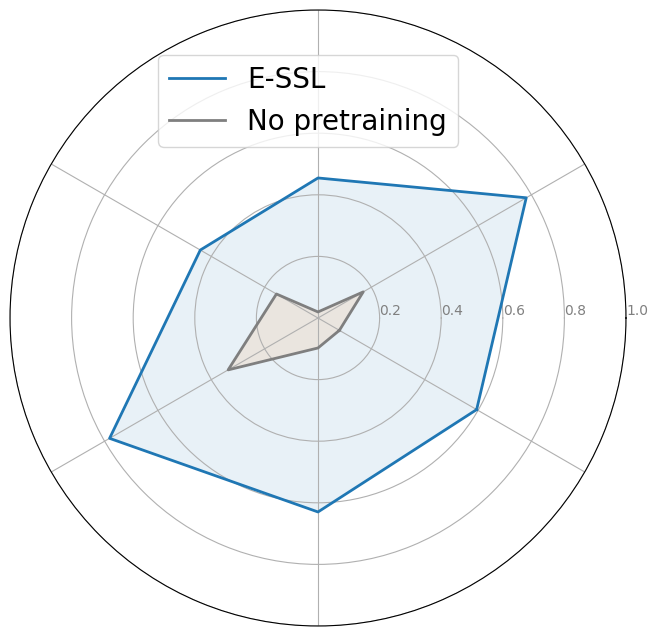

In [123]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Define the tasks (metrics) and model scores
tasks = ['Object rec.', 'Scene rec.', 'Semantic segm.', "Object segm." ,'Depth estim.', "Pose est."]
num_vars = len(tasks)

# Example scores (normalized to a 0.0 - 1.0 scale)
best_model = [44.23, 
              41.59, 
              34.69, 
              36.05,
              0.756, 
              0.137]

best_model2 = [40.8, 
              40.974,  
              32.34, 
              35.762,
              0.795, 
              0.164]

random = [6.05, 
          9.25, 
          1.5, 
          12.734,
          1.128, 
          0.334]
#model_c = [0.95, 0.75, 0.92, 0.85, 0.50, 0.40]

# To close the radar chart, we must repeat the first value at the end of the list
best_model += best_model[:1]
best_model2 += best_model2[:1]

random += random[:1]

#Anchor Diffusion for Unsupervised Video Object Segmentation
#Deeper Depth Prediction with Fully Convolutional Residual Networks
#FlowNet 2.0: Evolution of Optical Flow Estimation with Deep Networks
#63.51 supervised
minimum = [100/1000, 
           100*1/365, 
           0,
           0,
           1.41,
           0.37]
maximum = [74.3, 
           53.2, 
           76.3, 
           81.7,
           0.573, 
           0]
minimum += minimum[:1]
maximum += maximum[:1]
minimum = np.array(minimum)
maximum = np.array(maximum)
print(len(best_model), len(minimum), len(maximum))

best_model = abs((np.array(best_model) - minimum)/(maximum-minimum))
best_model2 = abs((np.array(best_model2) - minimum)/(maximum-minimum))

random = abs((np.array(random) - minimum)/(maximum-minimum))

#random += model_c[:1]

# 2. Calculate the angle for each task on the circle
# We divide 2 * pi by the number of tasks
angles = ((np.linspace(0, 2 * np.pi, num_vars, endpoint=False)- np.pi/6)% (2*np.pi)).tolist()
angles += angles[:1]  # Close the loop by repeating the first angle

# 3. Initialize the plot with polar coordinates
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

# Fix axis to display the task names
#plt.xticks(angles[:-1], tasks, color='black', size=12)
plt.xticks(angles[:-1], [""]*(len(angles)-1), color='black', size=12)

# Set the radial limit (e.g., 0 to 1 for normalized scores)
ax.set_rlabel_position(0)
plt.yticks(np.array([0.2, 0.4, 0.6, 0.8, 1.0]), ["0.2", "0.4", "0.6", "0.8", "1.0"], color="grey", size=10)
plt.ylim(0, 1)

# 4. Plot and fill each model
# Model A
ax.plot(angles, best_model, linewidth=2, linestyle='solid', label='E-SSL', color='tab:blue')
ax.fill(angles, best_model, alpha=0.1)

#ax.plot(angles, best_model2, linewidth=2, linestyle='solid', label='TC', color='tab:cyan')
#ax.fill(angles, best_model2, alpha=0.1)

# Model B
ax.plot(angles, random, linewidth=2, linestyle='solid', label='No pretraining', color='tab:grey')
ax.fill(angles, random, alpha=0.1)

# Model C
#ax.plot(angles, model_c, linewidth=2, linestyle='solid', label='Model C (Ensemble)')
#ax.fill(angles, model_c, alpha=0.1)

# 5. Add Legend and Title
#plt.title('Normalized performance on vision tasks', size=20, color='black', y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(0.75, 0.95), fontsize=20)
plt.savefig("/home/arthur/postdoc/projects/Nymeria/spider2.svg", dpi=800)
plt.show()